# Week 5
結構：`main.ipynb`、`Codes/Quiz1.py`（含共用工具）、`Codes/Quiz2b.py`、`Codes/Quiz3.py`、`Data/`、`Outputs/`

每個 Quiz 分多個 cell，可單獨重跑；資料不存在會自動下載；所有圖片存成 `Outputs/Q{n}_*.png`，模型存成 `Outputs/q{n}_*.pt`（Quiz 2 的檔名為 `Q2b_*` / `q2b_*`）；所有訓練都有 early stopping

**結果總覽**

| Quiz | 任務 | 主要結論 |
|---|---|---|
| 1 | Oxford5k 影像檢索（CNN vs ViT） | 微調使 mAP 由約 0.52–0.55 提升到約 0.70–0.72；微調後 CNN（ResNet-18）略優於 ViT-B/16，但差距小，僅單一 seed、204 個 query |
| 2 | UPMC Food-101 多模態分類（影像 + 食譜文字，101 類） | 融合（Accuracy 0.949）明顯優於最佳單模態（文字 0.867、影像 0.788）；CLIP 影像編碼器遠優於 ResNet-50（+19.6 pt）；concat 與 gated 融合相當、late 略低 |
| 3 | Flickr8k Image Captioning | 由 Week 4 → CLIP+LSTM → CLIP+GPT-2，BLEU-4 與 BERTScore 逐步提升；CLIP+GPT-2 的 BERTScore 高於 BLIP |

In [1]:
# 只需執行一次（Colab / 新環境）
# !pip install -q transformers datasets sacrebleu bert-score scikit-learn huggingface_hub

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / "Codes"))
import Quiz1 as q1
paths = q1.get_paths()
print(paths)

{'root': PosixPath('/cluster/home/m315832001/class/MMIP/week5'), 'codes': PosixPath('/cluster/home/m315832001/class/MMIP/week5/Codes'), 'data': PosixPath('/cluster/home/m315832001/class/MMIP/week5/Data'), 'outputs': PosixPath('/cluster/home/m315832001/class/MMIP/week5/Outputs')}


## Quiz 1：影像檢索任務 (Oxford5k 影像檢索)

**實驗設計**
- 資料：Oxford5k（5,062 張），取 11 個地標的 good+ok 影像為有標註資料，每個地標依 50% / 15% / 35% 切成 train / val / test；另抽 400 / 100 張無標註影像當「其他」類別加入 train / val，並自檢索庫移除
- 檢索庫 gallery = test 有標註影像 + 其餘 3,718 張 distractor（共 3,922 張）；query = test 有標註影像（204 張，以影像本身查詢並排除自己）
- 模型：CNN 與 ViT-B/16 皆為 ImageNet 預訓練，只微調最後階段（CNN 的 layer4／ViT 最後 2 個 block）+ 256 維投影 + cosine 分類頭（11 地標 + 其他），以 val loss 做 early stopping
- 另外加入 zero-shot（不微調、直接用 backbone 特徵）作對照，讓「微調是否有效」與「CNN vs ViT」兩個問題都能被觀察到
- 指標：mAP、Recall@1、Recall@5

### 1-1 自行準備影像檢索資料集

downloading https://www.robots.ox.ac.uk/~vgg/data/oxbuildings/oxbuild_images-v1.tgz
  0%
  10%
  20%
  30%
  40%
  50%
  60%
  70%
  80%
  90%
  100%
downloading https://www.robots.ox.ac.uk/~vgg/data/oxbuildings/gt_files_170407.tgz
  100%
landmarks=11 | train=682 val=181 queries=204 gallery=3922 (distractors in gallery=3718)


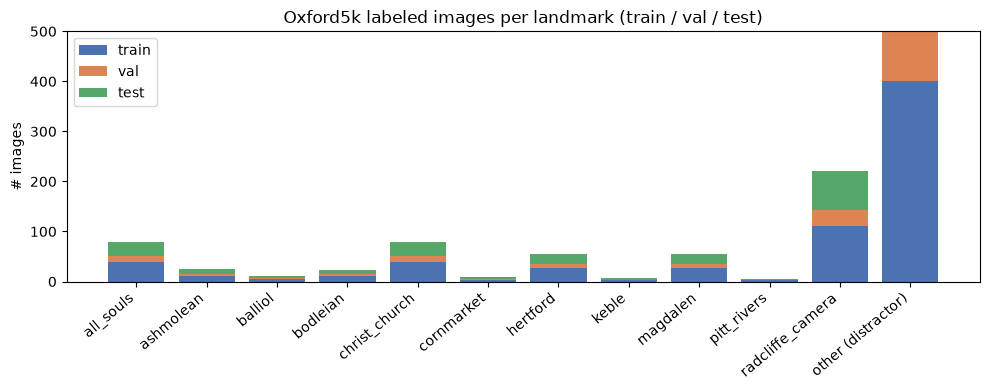

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q1_dataset_overview.png


In [3]:
# 1-1 下載資料、解析 ground truth、切分 train/val/test
ctx1 = q1.prepare_oxford(paths)
q1.plot_dataset_overview(ctx1)

### 1-2 建立並訓練影像檢索模型 (CNN & ViT)

In [4]:
# 1-2 訓練 CNN（early stopping，存成 Outputs/q1_cnn.pt）
q1.train_model(ctx1, 'cnn')

[cnn] ep1 train_loss=1.7410 val_loss=0.8530 val_acc=0.735
[cnn] ep2 train_loss=0.6095 val_loss=0.4927 val_acc=0.851
[cnn] ep3 train_loss=0.3178 val_loss=0.3991 val_acc=0.906
[cnn] ep4 train_loss=0.1761 val_loss=0.3446 val_acc=0.901
[cnn] ep5 train_loss=0.1155 val_loss=0.3795 val_acc=0.901
[cnn] ep6 train_loss=0.0996 val_loss=0.4350 val_acc=0.878
[cnn] ep7 train_loss=0.0684 val_loss=0.3185 val_acc=0.928
[cnn] ep8 train_loss=0.0459 val_loss=0.3572 val_acc=0.928
[cnn] ep9 train_loss=0.0392 val_loss=0.2897 val_acc=0.928
[cnn] ep10 train_loss=0.0207 val_loss=0.3303 val_acc=0.928
[cnn] ep11 train_loss=0.0382 val_loss=0.3124 val_acc=0.917
[cnn] ep12 train_loss=0.0358 val_loss=0.3320 val_acc=0.934
[cnn] ep13 train_loss=0.0195 val_loss=0.3760 val_acc=0.923
early stop, best epoch = 9
[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/q1_cnn.pt


{'train_loss': [1.7409854474521818,
  0.6094628075758616,
  0.3177945163278353,
  0.1761090542588915,
  0.11554302071176824,
  0.09959965447584788,
  0.06843231290224053,
  0.045901708371405094,
  0.039229284589444954,
  0.02071386169908302,
  0.03824725090747788,
  0.03581336852706348,
  0.01952922748335238],
 'val_loss': [0.8530408959033081,
  0.4927253341971181,
  0.39908166126816313,
  0.34461160045302375,
  0.37953253958929967,
  0.43502119726897603,
  0.3185418768276497,
  0.35718912997627783,
  0.289731538345142,
  0.3302519180045273,
  0.3124320888531636,
  0.33204259582054263,
  0.37600089980093815],
 'val_acc': [0.7348066298342542,
  0.850828729281768,
  0.9060773480662984,
  0.9005524861878453,
  0.9005524861878453,
  0.8784530386740331,
  0.9281767955801105,
  0.9281767955801105,
  0.9281767955801105,
  0.9281767955801105,
  0.9171270718232044,
  0.9337016574585635,
  0.9226519337016574],
 'best_epoch': 9,
 'train_time_s': 45.44796109199524}

[vit] ep1 train_loss=1.0522 val_loss=0.5557 val_acc=0.867
[vit] ep2 train_loss=0.3091 val_loss=0.3921 val_acc=0.895
[vit] ep3 train_loss=0.1409 val_loss=0.3164 val_acc=0.906
[vit] ep4 train_loss=0.0743 val_loss=0.3015 val_acc=0.928
[vit] ep5 train_loss=0.0245 val_loss=0.3172 val_acc=0.912
[vit] ep6 train_loss=0.0273 val_loss=0.2802 val_acc=0.912
[vit] ep7 train_loss=0.0195 val_loss=0.3465 val_acc=0.901
[vit] ep8 train_loss=0.0205 val_loss=0.3403 val_acc=0.890
[vit] ep9 train_loss=0.0121 val_loss=0.3187 val_acc=0.912
[vit] ep10 train_loss=0.0246 val_loss=0.3094 val_acc=0.912
early stop, best epoch = 6
[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/q1_vit.pt


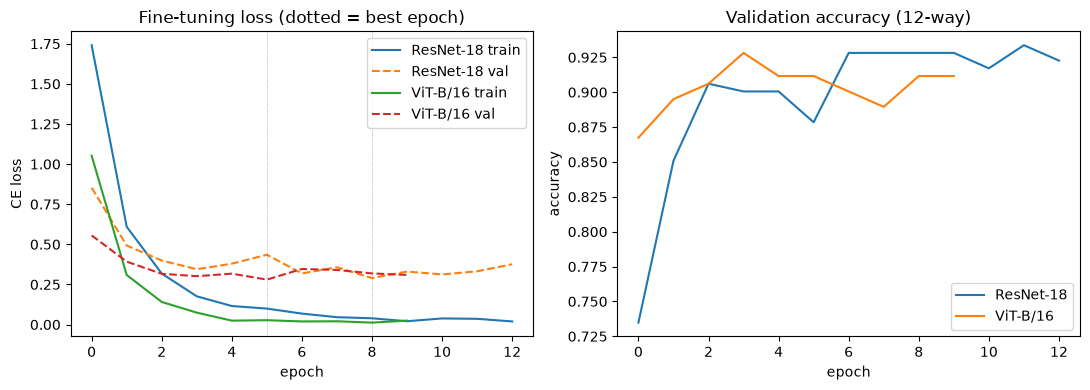

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q1_training_curves.png


In [ ]:
# 訓練 ViT（early stopping，存成 Outputs/q1_vit.pt）
q1.train_model(ctx1, 'vit')
q1.plot_training_curves(ctx1)

### 1-3 檢索評估：zero-shot vs 微調後，CNN vs ViT

In [ ]:
# 檢索評估：zero-shot vs 微調後，CNN vs ViT
df1 = q1.evaluate_all(ctx1)
df1

{'Model': 'ResNet-18 (zero-shot)', 'mAP': np.float64(0.5154518539631726), 'Recall@1': np.float64(0.7843137254901961), 'Recall@5': np.float64(0.8774509803921569), 'Params_M': 11.176512, 'Embed_s_per_img': 0.005578998398379609}
{'Model': 'ResNet-18 (fine-tuned)', 'mAP': np.float64(0.7211874868857273), 'Recall@1': np.float64(0.8774509803921569), 'Recall@5': np.float64(0.9264705882352942), 'Params_M': 11.176512, 'Embed_s_per_img': 0.003558322460538328}
{'Model': 'ViT-B/16 (zero-shot)', 'mAP': np.float64(0.5478703559052702), 'Recall@1': np.float64(0.7647058823529411), 'Recall@5': np.float64(0.8872549019607843), 'Params_M': 85.798656, 'Embed_s_per_img': 0.0034599898725915235}
{'Model': 'ViT-B/16 (fine-tuned)', 'mAP': np.float64(0.7040594642228319), 'Recall@1': np.float64(0.7990196078431373), 'Recall@5': np.float64(0.9019607843137255), 'Params_M': 85.798656, 'Embed_s_per_img': 0.0033946266470971853}


,mAP,Recall@1,Recall@5,Params_M,Embed_s_per_img
Model,,,,,
ResNet-18 (zero-shot),0.5155,0.7843,0.8775,11.1765,0.0056
ResNet-18 (fine-tuned),0.7212,0.8775,0.9265,11.1765,0.0036
ViT-B/16 (zero-shot),0.5479,0.7647,0.8873,85.7987,0.0035
ViT-B/16 (fine-tuned),0.7041,0.7990,0.9020,85.7987,0.0034


### 1-4 圖表與檢索結果展示

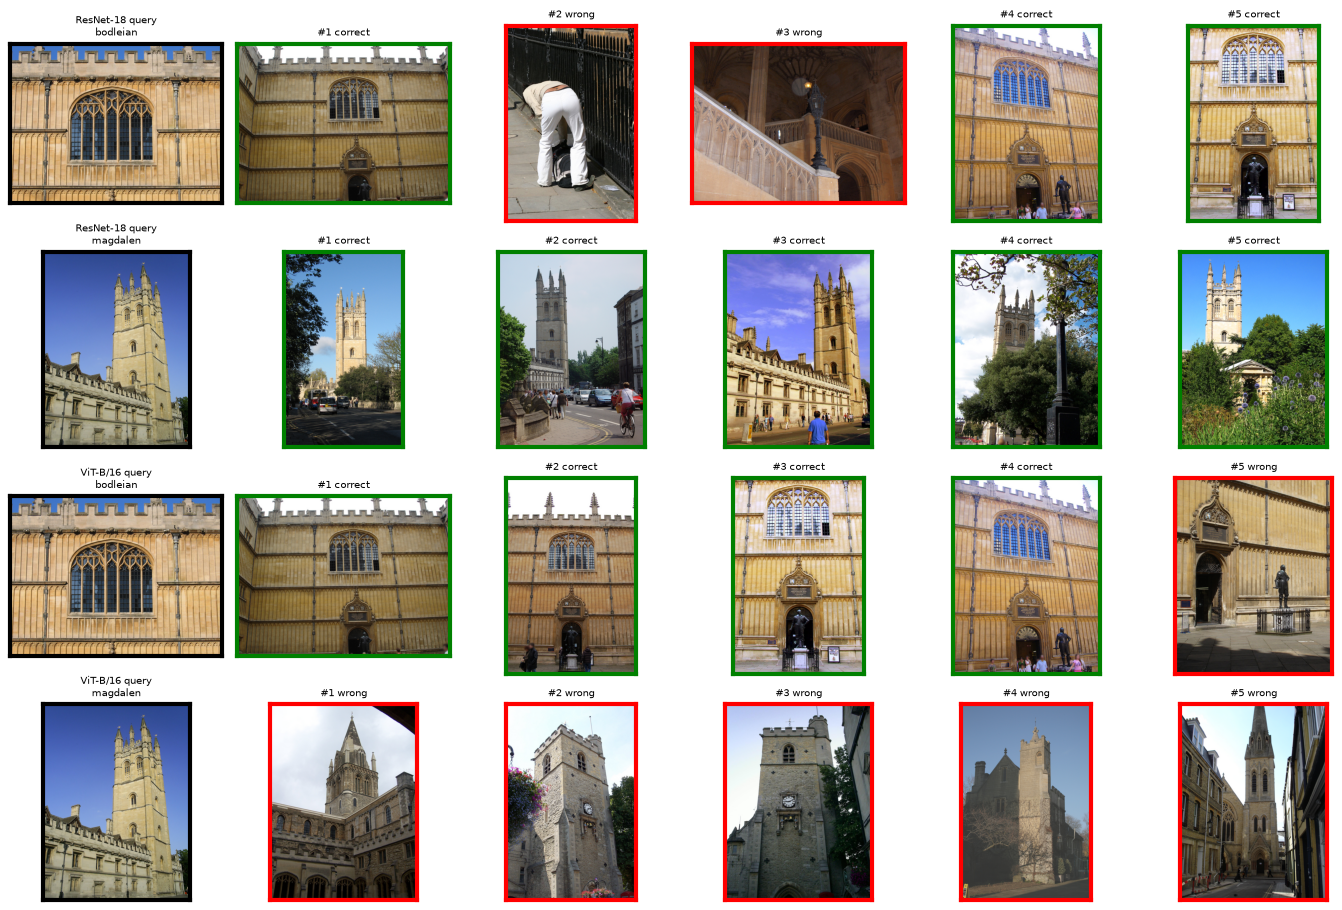

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q1_retrieval_examples.png


In [8]:
q1.plot_retrieval_examples(ctx1, n_q=2, k=5, seed=76)

### 1-5 效能評估

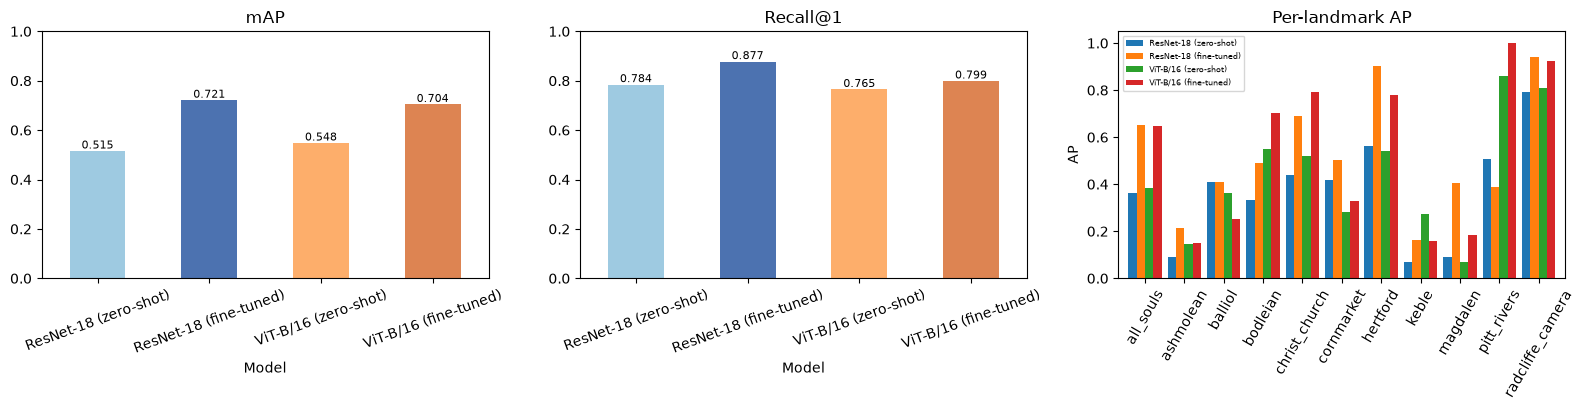

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q1_method_comparison.png


In [7]:
q1.plot_results(ctx1, df1)

### Quiz 1 結果分析

| 模型 | mAP | Recall@1 | Recall@5 | 參數量 |
|---|---|---|---|---|
| ResNet-18 zero-shot | 0.515 | 0.784 | 0.877 | 11.2M |
| ResNet-18 微調後 | **0.721** | **0.877** | **0.926** | 11.2M |
| ViT-B/16 zero-shot | 0.548 | 0.765 | 0.887 | 85.8M |
| ViT-B/16 微調後 | 0.704 | 0.799 | 0.902 | 85.8M |

1. **微調確實有效**   
mAP 提升 ResNet-18 +0.206、ViT +0.156zero-shot 時 ViT 略好（0.548 vs 0.515），但微調後 ResNet-18 反超，mAP、Recall@1、Recall@5 三項都較高可能原因（未做消融驗證）：訓練影像只有 682 張，參數較少的 CNN 微調 layer4 比較容易適應；ViT 只微調最後 2 個 block，適應幅度較小

2. **兩種 backbone 的差距不大**   
mAP 只差 0.017；Recall@1 差 0.078，約相當於 204 個 query 中的 16 個，但只有單一 seed，沒有信賴區間較保守的結論是「微調後 CNN 略優，且參數量只有 ViT 的 1/8」Recall@5 四組都落在 0.88–0.93，區分力有限，主要看 mAP 與 Recall@1

3. **Early stopping 有發揮作用**   
ResNet-18 在第 9 epoch 達最佳 val loss（0.290，於第 13 epoch 停止），ViT 在第 6 epoch（0.280，於第 10 epoch 停止）train loss 之後降到 0.02 左右、val loss 卻停在 0.28–0.38，顯示小資料下很快過擬合；val accuracy 約 0.91–0.93

4. **各地標難度差異很大（見 `Q1_method_comparison.png` 右圖）**   
radcliffe_camera、hertford、christ_church 的 AP 較高（微調後 AP 約 0.7–0.9）；ashmolean、keble、magdalen 最難，多數模型 AP 約 0.4 以下微調也並非對每個地標都有益，例如 pitt_rivers 在 ResNet-18 微調後 AP 下降（約 0.51 → 0.39）、balliol 在 ViT 微調後下降（約 0.36 → 0.25），推測與各地標訓練張數少、外觀相近有關
5. **檢索範例（`Q1_retrieval_examples.png`）** 僅作為定性展示，不代表整體表現

In [ ]:
# （選用）單張新影像推論
# q1.search(ctx1, 'vit', paths['data']/'oxford5k'/'images'/f"{ctx1['test_names'][0]}.jpg")

## Quiz 2：多模態深度學習神經網路 (UPMC Food-101, 影像 + 食譜文字，101類)

**實驗設計**
1. **Backbone 網格**（皆凍結、先抽特徵並快取）：影像 ResNet-50（監督式）vs CLIP ViT-B/16 影像編碼器（圖文對比式）；文字 BERT-base（128 tokens）vs CLIP 文字編碼器（77 tokens）共 4 組單模態基準 + 4 組 concat 融合
2. **融合策略比較**：用網格中最佳的組合，比較 concat、late（各模態 logits 平均）、gated（學習式門控）
3. **分析**：逐類別增益（影像 vs 文字 vs 融合）、模態消融（推論時遮掉一個模態）、最常被混淆的類別
4. 每組 3 個 seed 取 mean ± std；early stopping 以 val Macro-F1 為準；指標含 Accuracy、Macro-F1、Top-5 Accuracy（101 類）

**資料**：UPMC Food-101，每筆為一張影像加一段網頁文字程式先找 `Data/upmc_food101/`，沒有才用 kagglehub 下載，資料夾結構與文字格式採自動偵測並印出結果本次偵測到 90,704 張影像、101 個類別資料夾，文字來自 `train_titles.csv`（67,972 筆）與 `test_titles.csv`（22,716 筆），圖文以檔名配對train 再分層切出 10% 當 val，最後 train / val / test = 61,177 / 6,795 / 22,716，沒有空文字

### 2-1 下載影像與文字的多模態訓練資料集

/cluster/home/m315832001/miniconda3/envs/mmip_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


images=90704 | class folders=101
table test_titles.csv: rows=22716 img_col=0 label_col=2 text_col=1
table train_titles.csv: rows=67972 img_col=0 label_col=2 text_col=1
{'train': 61177, 'val': 6795, 'test': 22716} | empty text: {'train': '0.0%', 'val': '0.0%', 'test': '0.0%'}


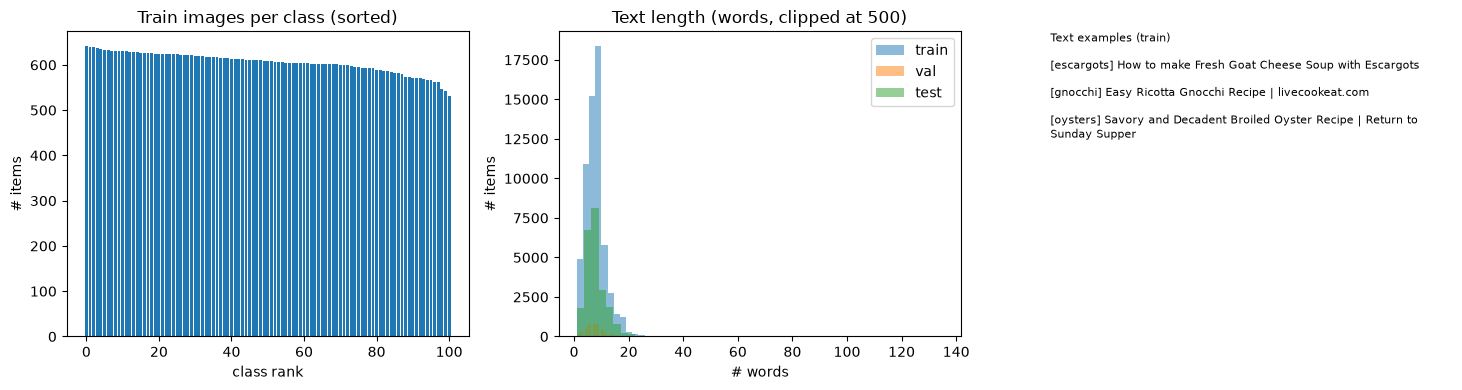

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q2_data_overview.png


In [2]:
import Quiz2 as q2
ctx2 = q2.prepare_upmc(paths)
# 先小規模試跑可改成：q2b.prepare_upmc(paths, max_per_class_train=300, max_per_class_test=100)
q2.plot_data_overview(ctx2)

### 2-2 使用影像與文字 Backbone 萃取特徵

In [3]:
# 2b-2 抽特徵（2 個影像 + 2 個文字 backbone，快取）
q2.extract_all(ctx2)

resnet50: loaded from cache feats_resnet50_None_None.pt (61177, 2048)
clip_img: loaded from cache feats_clip_img_None_None.pt (61177, 512)
bert: loaded from cache feats_bert_None_None.pt (61177, 768)
clip_txt: loaded from cache feats_clip_txt_None_None.pt (61177, 512)


### 2-3 融合特徵後建立分類模型

In [5]:
# 2b-3 Backbone 網格：4 組單模態 + 4 組 concat 融合（每組 3 seeds，early stopping）
df2 = q2.run_backbone_grid(ctx2)
df2

img:resnet50 {'Accuracy': np.float64(0.5923), 'Accuracy_std': np.float64(0.002), 'Macro-F1': np.float64(0.5898), 'Macro-F1_std': np.float64(0.0018), 'Top5-Acc': np.float64(0.8051), 'Top5-Acc_std': np.float64(0.0024)}
img:clip_img {'Accuracy': np.float64(0.7879), 'Accuracy_std': np.float64(0.0005), 'Macro-F1': np.float64(0.787), 'Macro-F1_std': np.float64(0.0005), 'Top5-Acc': np.float64(0.9196), 'Top5-Acc_std': np.float64(0.0005)}
txt:bert {'Accuracy': np.float64(0.8437), 'Accuracy_std': np.float64(0.001), 'Macro-F1': np.float64(0.843), 'Macro-F1_std': np.float64(0.001), 'Top5-Acc': np.float64(0.8916), 'Top5-Acc_std': np.float64(0.0004)}
txt:clip_txt {'Accuracy': np.float64(0.8671), 'Accuracy_std': np.float64(0.0006), 'Macro-F1': np.float64(0.8669), 'Macro-F1_std': np.float64(0.0005), 'Top5-Acc': np.float64(0.9075), 'Top5-Acc_std': np.float64(0.0005)}
resnet50+bert {'Accuracy': np.float64(0.9003), 'Accuracy_std': np.float64(0.0007), 'Macro-F1': np.float64(0.8996), 'Macro-F1_std': np.flo

,Type,Fusion,Accuracy,Accuracy_std,Macro-F1,Macro-F1_std,Top5-Acc,Top5-Acc_std
img:resnet50,single-modal,-,0.5923,0.0020,0.5898,0.0018,0.8051,0.0024
img:clip_img,single-modal,-,0.7879,0.0005,0.7870,0.0005,0.9196,0.0005
txt:bert,single-modal,-,0.8437,0.0010,0.8430,0.0010,0.8916,0.0004
txt:clip_txt,single-modal,-,0.8671,0.0006,0.8669,0.0005,0.9075,0.0005
resnet50+bert,fusion,concat,0.9003,0.0007,0.8996,0.0007,0.9614,0.0009
resnet50+clip_txt,fusion,concat,0.9192,0.0004,0.9189,0.0003,0.9679,0.0003
clip_img+bert,fusion,concat,0.9393,0.0005,0.9389,0.0004,0.9833,0.0004
clip_img+clip_txt,fusion,concat,0.9489,0.0002,0.9486,0.0003,0.9851,0.0004


In [6]:
# 2b-4 融合策略比較（用網格中最佳組合）：late / gated vs concat
df2 = q2.run_fusion_study(ctx2)
df2

fusion study on clip_img+clip_txt
clip_img+clip_txt|late {'Accuracy': np.float64(0.9418), 'Accuracy_std': np.float64(0.0007), 'Macro-F1': np.float64(0.9416), 'Macro-F1_std': np.float64(0.0006), 'Top5-Acc': np.float64(0.9842), 'Top5-Acc_std': np.float64(0.0004)}
clip_img+clip_txt|gated {'Accuracy': np.float64(0.9482), 'Accuracy_std': np.float64(0.0008), 'Macro-F1': np.float64(0.9478), 'Macro-F1_std': np.float64(0.0008), 'Top5-Acc': np.float64(0.9848), 'Top5-Acc_std': np.float64(0.0005)}


,Type,Fusion,Accuracy,Accuracy_std,Macro-F1,Macro-F1_std,Top5-Acc,Top5-Acc_std
img:resnet50,single-modal,-,0.5923,0.0020,0.5898,0.0018,0.8051,0.0024
img:clip_img,single-modal,-,0.7879,0.0005,0.7870,0.0005,0.9196,0.0005
txt:bert,single-modal,-,0.8437,0.0010,0.8430,0.0010,0.8916,0.0004
txt:clip_txt,single-modal,-,0.8671,0.0006,0.8669,0.0005,0.9075,0.0005
resnet50+bert,fusion,concat,0.9003,0.0007,0.8996,0.0007,0.9614,0.0009
resnet50+clip_txt,fusion,concat,0.9192,0.0004,0.9189,0.0003,0.9679,0.0003
clip_img+bert,fusion,concat,0.9393,0.0005,0.9389,0.0004,0.9833,0.0004
clip_img+clip_txt,fusion,concat,0.9489,0.0002,0.9486,0.0003,0.9851,0.0004
clip_img+clip_txt|late,fusion,late,0.9418,0.0007,0.9416,0.0006,0.9842,0.0004
clip_img+clip_txt|gated,fusion,gated,0.9482,0.0008,0.9478,0.0008,0.9848,0.0005


### 2-4 多模態分類推論

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 51065.55it/s]


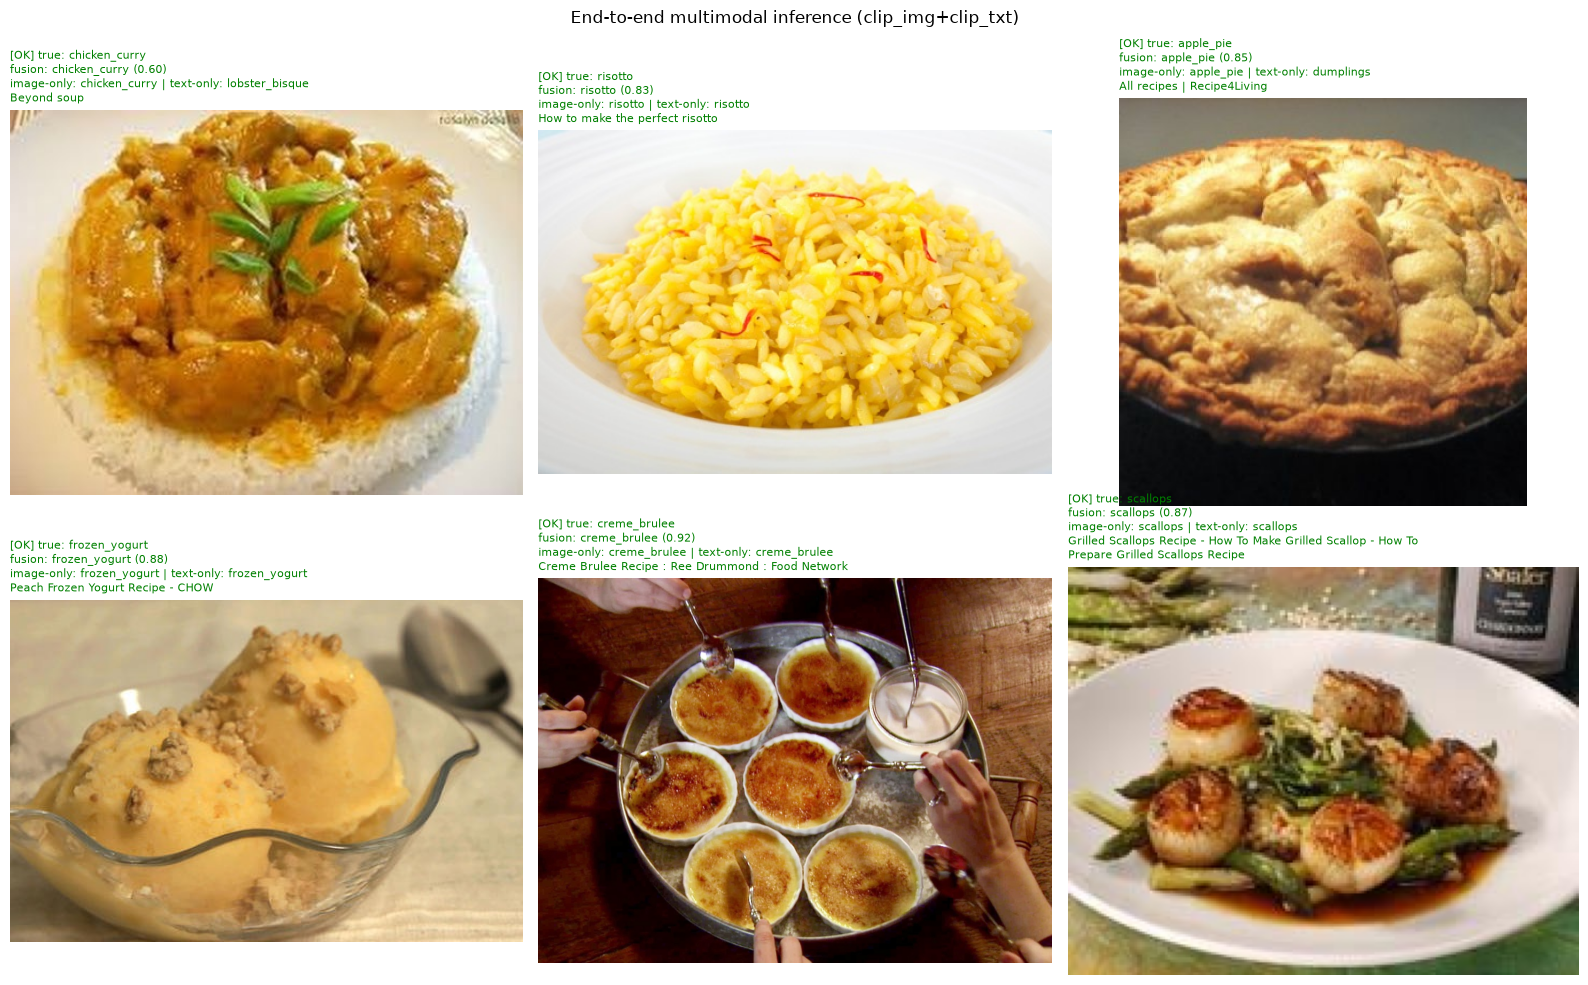

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q2_predictions.png


In [7]:
#  端到端推論展示（原始影像 + 原始文字；並列融合 / 僅影像 / 僅文字的預測）
q2.plot_predictions(ctx2)

### 2-5 實驗結果比較

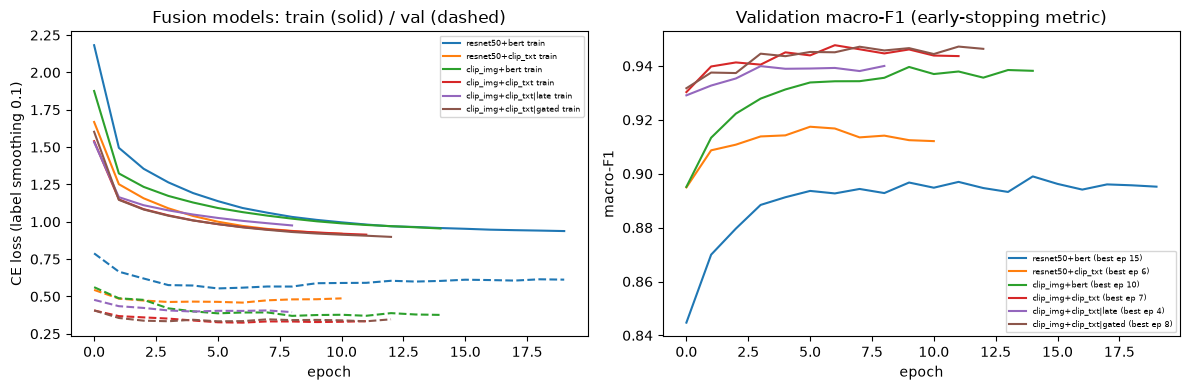

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q2_training_curves.png


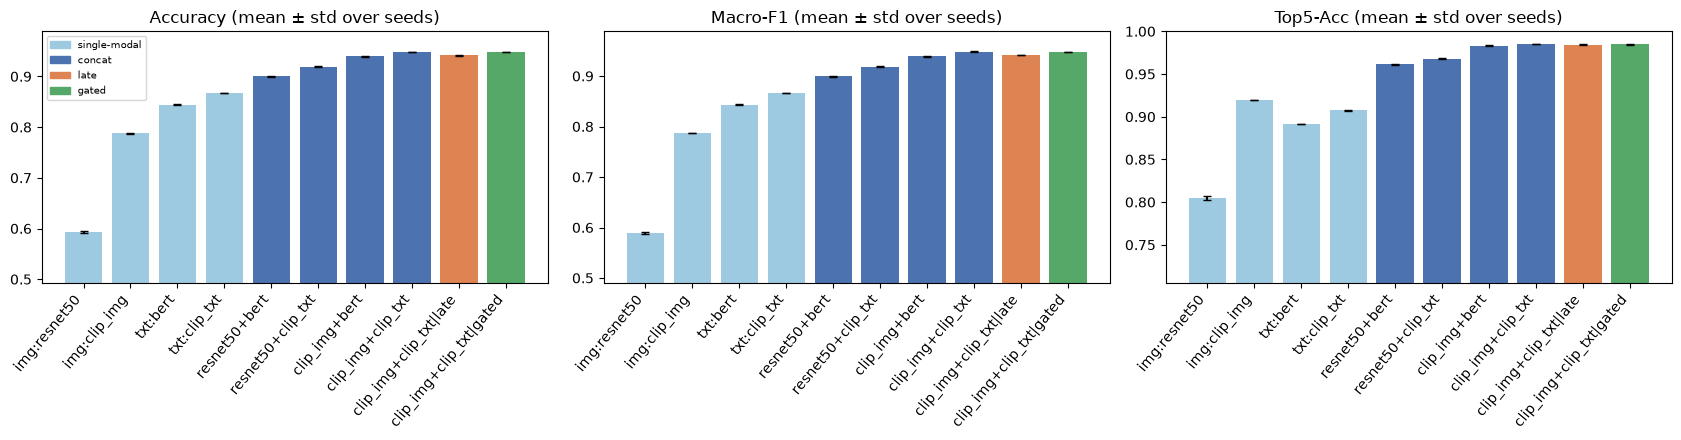

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q2_model_comparison.png


In [8]:
q2.plot_training_curves(ctx2)
q2.plot_comparison(ctx2, df2)

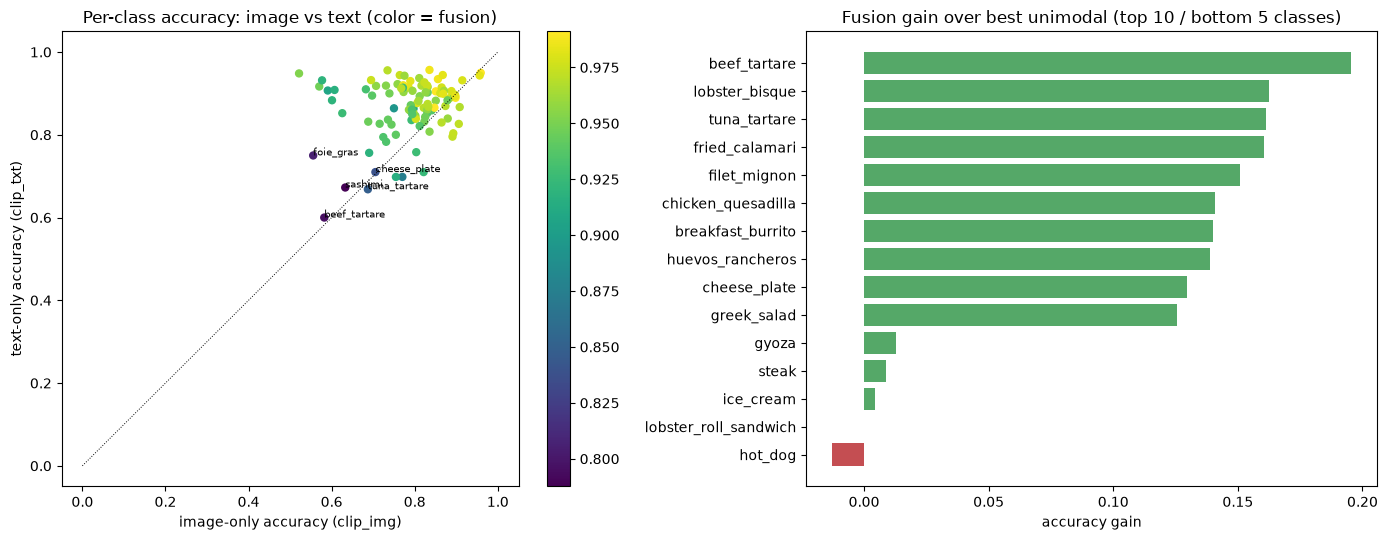

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q2_class_analysis.png


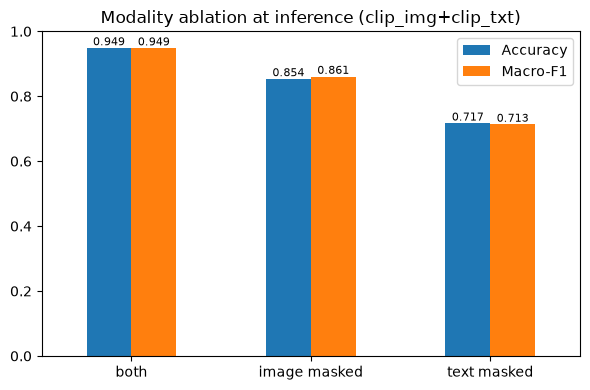

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q2_modality_ablation.png


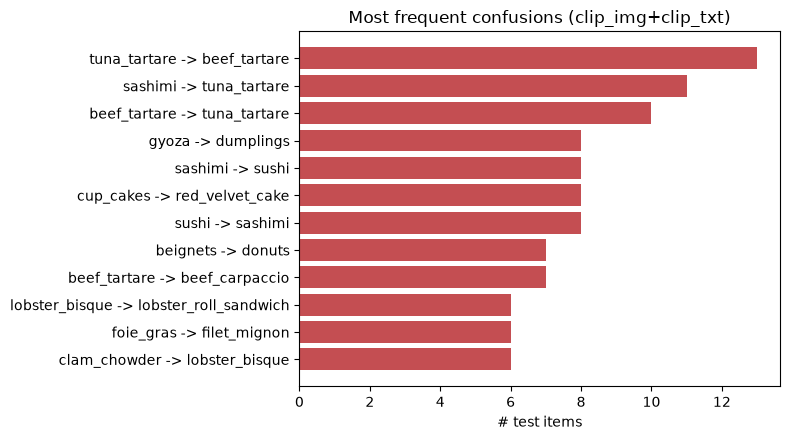

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q2_top_confusions.png


,Accuracy,Macro-F1
both,0.9489,0.9485
image masked,0.8536,0.8608
text masked,0.7169,0.7132


In [9]:
# 2b-5 分析：逐類別增益、模態消融、最常見混淆
class_df = q2.plot_class_analysis(ctx2)
abl_df = q2.modality_ablation(ctx2)
q2.plot_top_confusions(ctx2)
abl_df

### Quiz 2 結果分析

測試集 22,716 筆、101 類（每類約 225 筆）；下表為 3 個 seed 的平均（標準差皆 ≤ 0.002）

| 實驗 | Accuracy | Macro-F1 | Top-5 Acc |
|---|---|---|---|
| img:resnet50 | 0.592 | 0.590 | 0.805 |
| img:clip_img | 0.788 | 0.787 | 0.920 |
| txt:bert | 0.844 | 0.843 | 0.892 |
| txt:clip_txt | 0.867 | 0.867 | 0.908 |
| resnet50 + bert（concat） | 0.900 | 0.900 | 0.961 |
| resnet50 + clip_txt（concat） | 0.919 | 0.919 | 0.968 |
| clip_img + bert（concat） | 0.939 | 0.939 | 0.983 |
| **clip_img + clip_txt（concat）** | **0.949** | **0.949** | **0.985** |
| clip_img + clip_txt（late） | 0.942 | 0.942 | 0.984 |
| clip_img + clip_txt（gated） | 0.948 | 0.948 | 0.985 |

1. **Backbone 的選擇有很大的鑑別度，尤其是影像**   
CLIP 影像編碼器的 Accuracy 比 ResNet-50 高 19.6 %（0.788 vs 0.592）；文字端 CLIP 文字編碼器比 BERT 高 2.3 %（0.867 vs 0.844）測試集 22,716 筆下標準誤約 0.2–0.3 %，且 seed 標準差 ≤ 0.002  

2. **單模態中文字強於影像，但 Top-5 的排序不同**   
Top-1 以 CLIP 文字最高（0.867）、其次 BERT（0.844）、CLIP 影像（0.788）、ResNet-50（0.592）；  
但 Top-5 是 CLIP 影像（0.920）高於 BERT（0.892）與 CLIP 文字（0.908）  
也就是文字較能直接點出正確類別，影像較擅長把答案縮到少數候選文字較強的原因推測是網頁文字常直接出現菜名或食材，這點未另外驗證

3. **多模態融合明顯優於任何單模態，這是最穩健的結論**   
每組融合都高於其組成中較強的單模態：resnet50 + bert 為 0.900（較 BERT +5.6 pt）；clip_img + clip_txt 為 0.949（較 CLIP 文字 +8.2 pt），Top-5 達 0.985即使影像端是較弱的 ResNet-50（0.592），加入後仍能把 CLIP 文字從 0.867 提升到 0.919（+5.2 pt），顯示兩個模態互補
4. **融合時影像編碼器的影響大於文字編碼器**   
將 ResNet-50 換成 CLIP 影像編碼器可再提升 3.0–3.9 pt（0.900 → 0.939、0.919 → 0.949）；將 BERT 換成 CLIP 文字編碼器只提升 1.0–1.9 pt（0.900 → 0.919、0.939 → 0.949）四組排序一致：clip+clip > clip_img+bert > resnet+clip_txt > resnet+bert 

5. **融合策略：concat 與 gated 相當，late 略低**   
concat 0.949、gated 0.948，差 0.07 pt，在誤差內（視為持平）；late 為 0.942，低約 0.7 pt，且超出 seed 標準差，符合「兩個模態在決策前沒有互動」的預期

6. **訓練行為（`Q2b_training_curves.png`）**   
val macro-F1 很快進入高原，early stopping 選到的最佳 epoch 為 4–15（resnet50+bert 最晚，在第 15；late 最早，在第 4）  
圖中 train loss（約 0.9）高於 val loss（約 0.3–0.6），不代表欠擬合：但訓練時有 label smoothing（0.1）與 dropout，兩者會墊高 train loss，因此這兩條曲線的數值不宜直接比較  
7. **模態消融（`Q2b_modality_ablation.png`，clip_img+clip_txt concat）**   
正常輸入 Accuracy 0.949；遮掉影像降到 0.854（−9.5 pt），遮掉文字降到 0.717（−23.2 pt），模型明顯更依賴文字  

8. **逐類別分析（`Q2b_class_analysis.png`）**   
幾乎所有類別的文字準確率都高於影像  
融合後最難的類別（Accuracy 約 0.8–0.88，依散點圖顏色估計）是 foie_gras、cheese_plate、sashimi、tuna_tartare、beef_tartare  
融合增益（融合減去兩個單模態中較高者）最大的是 beef_tartare（約 +0.20）、lobster_bisque、tuna_tartare、fried_calamari（皆約 +0.16）、filet_mignon（約 +0.15）；gyoza、steak、ice_cream、lobster_roll_sandwich 幾乎沒有增益，只有 hot_dog 略為下降（約 −0.01）

9. **主要錯誤是語意或外觀相近的類別（`Q2b_top_confusions.png`）**   
最常見的混淆是 tuna_tartare → beef_tartare（13 筆）、sashimi → tuna_tartare（11）、beef_tartare → tuna_tartare（10），其次是 gyoza → dumplings、sashimi ↔ sushi、cup_cakes → red_velvet_cake、beignets → donuts 等（各 7–8 筆）這些都是難以區分的相近類別，且單一混淆對的筆數都不多（最多 13 筆） 

## Quiz 3：CLIP Image Captioning（Flick8k）

**實驗設計**（Flickr8k，Hugging Face `jxie/flickr8k`，train / val / test = 6,000 / 1,000 / 1,000 張，每張 5 句參考描述）
- **W4_ResNet50+LSTM**：Week 4 方法 A，**直接讀取 Week 4 存的 `Data/q4_cnn_lstm.pt`（不重訓）**，使用 Week 4 自己的詞彙表與貪婪解碼，作為基準請將該檔案放在 `Outputs/`，或在 `q3.load_week4(ctx3, path=...)` 指定路徑
- **CLIP+LSTM**：只把 Encoder 換成 CLIP ViT-B/16，LSTM 解碼器架構相同（僅多一層輸入 LayerNorm），貪婪解碼，用來隔離「Encoder」的貢獻
- **CLIP+GPT2**：ClipCap 風格，CLIP 向量 → MLP 產生 10 個前綴 token → DistilGPT-2（beam=3），同時更換 Encoder 與 Decoder
- **W4_BLIP**（參考）：Week 4 方法 B，預訓練模型
- 評估：BLEU-4（sacrebleu、5 句參考）、BERTScore F1（原始與 rescaled）、端到端延遲（batch=1）所有新訓練的模型都有 early stopping（val loss）

### 3-1 資料準備，沿用 Week 4 的 Image Captioning 資料集 Flick8k

In [12]:
import Quiz3 as q3
ctx3 = q3.prepare_flickr(paths)   # 自動下載 jxie/flickr8k
q3.extract_features(ctx3)
q3.build_vocab(ctx3)

Old caching folder /cluster/home/m315832001/class/MMIP/week5/Data/flickr8k_hf/jxie___flickr8k/default/0.0.0/56f58c967835f7c508d684f36bd7897cca9d7634 for dataset flickr8k exists but no data were found. Removing it. 
Generating test split: 100%|██████████| 1000/1000 [00:00<00:00, 1804.15 examples/s]


{'train': 6000, 'val': 1000, 'test': 1000} | refs/img: 5


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 55448.51it/s]


caption vocab: 2539


### 3-2 載入 Week 4 模型（.pt）+ 訓練 CLIP

loaded week4_cnn_lstm.pt | vocab=2539 | params=2.82M
[CLIP+LSTM] ep1 train=4.5890 val=3.7609
[CLIP+LSTM] ep2 train=3.6970 val=3.3518
[CLIP+LSTM] ep3 train=3.3976 val=3.1555
[CLIP+LSTM] ep4 train=3.2193 val=3.0307
[CLIP+LSTM] ep5 train=3.0958 val=2.9436
[CLIP+LSTM] ep6 train=2.9963 val=2.8794
[CLIP+LSTM] ep7 train=2.9185 val=2.8277
[CLIP+LSTM] ep8 train=2.8539 val=2.7898
[CLIP+LSTM] ep9 train=2.7976 val=2.7617
[CLIP+LSTM] ep10 train=2.7485 val=2.7372
[CLIP+LSTM] ep11 train=2.7055 val=2.7171
[CLIP+LSTM] ep12 train=2.6680 val=2.7006
[CLIP+LSTM] ep13 train=2.6332 val=2.6935
[CLIP+LSTM] ep14 train=2.5989 val=2.6783
[CLIP+LSTM] ep15 train=2.5722 val=2.6741
[CLIP+LSTM] ep16 train=2.5457 val=2.6604
[CLIP+LSTM] ep17 train=2.5196 val=2.6551
[CLIP+LSTM] ep18 train=2.4949 val=2.6528
[CLIP+LSTM] ep19 train=2.4701 val=2.6421
[CLIP+LSTM] ep20 train=2.4510 val=2.6529
[CLIP+LSTM] ep21 train=2.4337 val=2.6437
[CLIP+LSTM] ep22 train=2.4135 val=2.6395
[CLIP+LSTM] ep23 train=2.3938 val=2.6368
[CLIP+LSTM] e

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 2097.76it/s]


[CLIP+GPT2] ep1 train=2.6010 val=2.3572
[CLIP+GPT2] ep2 train=2.1904 val=2.2691
[CLIP+GPT2] ep3 train=2.0162 val=2.2505
[CLIP+GPT2] ep4 train=1.8703 val=2.2600
[CLIP+GPT2] ep5 train=1.7438 val=2.2642
early stop, best epoch = 3


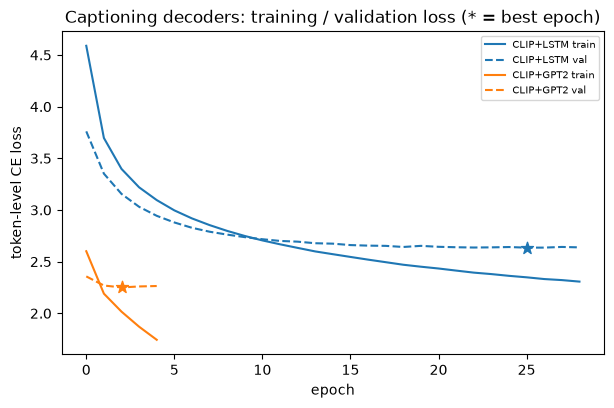

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q3_training_curves.png


In [ ]:
# Week 4 的 q4_cnn_lstm.pt 請放在 Outputs/，或改用 path 指定，例如：
# q3.load_week4(ctx3, path="../week4/Outputs/q4_cnn_lstm.pt")
q3.load_week4(ctx3)
q3.train_lstm(ctx3, 'CLIP+LSTM', 'clip', 'clip_lstm')
q3.train_clipcap(ctx3)
q3.plot_training_curves(ctx3)

In [14]:
# 3-3 產生描述 + 延遲；選用 Week 4 的 BLIP 當上限參考
q3.generate_test(ctx3)
q3.measure_latency(ctx3)
q3.add_blip(ctx3)          # 不需要可註解掉

W4_ResNet50+LSTM | e.g.: a brown dog is running through a field of a large black dog
CLIP+LSTM | e.g.: two dogs are playing in the snow


/cluster/home/m315832001/miniconda3/envs/mmip_env/lib/python3.11/site-packages/transformers/generation/utils.py:1464: UserWarning: Passing `no_repeat_ngram_size` with `inputs_embeds` and without `input_ids` to `generate` will apply n-gram constraints only to newly generated tokens, not to the prompt.
  warnings.warn(


CLIP+GPT2 | e.g.: two brown dogs are playing in the snow .


Loading weights: 100%|██████████| 473/473 [00:00<00:00, 50671.89it/s]


W4_BLIP | e.g.: two dogs playing in the snow


In [15]:
df3 = q3.text_metrics(ctx3)
df3

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 16227.73it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|██████████| 389/389 [00:00<00:00, 16745.36it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UN

W4_ResNet50+LSTM {'BLEU-4': 18.8413, 'BERTScore_F1': 0.9245, 'BERTScore_F1_rescaled': 0.5525, 'Avg_len': np.float64(10.75), 'Latency_s': 0.0069, 'Empty_captions': 0}


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 15209.08it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|██████████| 389/389 [00:00<00:00, 15774.77it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UN

CLIP+LSTM {'BLEU-4': 23.3198, 'BERTScore_F1': 0.9313, 'BERTScore_F1_rescaled': 0.5932, 'Avg_len': np.float64(10.054), 'Latency_s': 0.0073, 'Empty_captions': 0}


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 16835.73it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|██████████| 389/389 [00:00<00:00, 16095.97it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UN

CLIP+GPT2 {'BLEU-4': 25.5628, 'BERTScore_F1': 0.9375, 'BERTScore_F1_rescaled': 0.6298, 'Avg_len': np.float64(11.268), 'Latency_s': 0.0365, 'Empty_captions': 0}


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 13277.43it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|██████████| 389/389 [00:00<00:00, 17664.72it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UN

W4_BLIP {'BLEU-4': 26.6313, 'BERTScore_F1': 0.9335, 'BERTScore_F1_rescaled': 0.606, 'Avg_len': np.float64(6.845), 'Latency_s': 0.062, 'Empty_captions': 0}


,BLEU-4,BERTScore_F1,BERTScore_F1_rescaled,Avg_len,Latency_s,Empty_captions
W4_ResNet50+LSTM,18.8413,0.9245,0.5525,10.750,0.0069,0.0
CLIP+LSTM,23.3198,0.9313,0.5932,10.054,0.0073,0.0
CLIP+GPT2,25.5628,0.9375,0.6298,11.268,0.0365,0.0
W4_BLIP,26.6313,0.9335,0.6060,6.845,0.0620,0.0


### 實驗結果

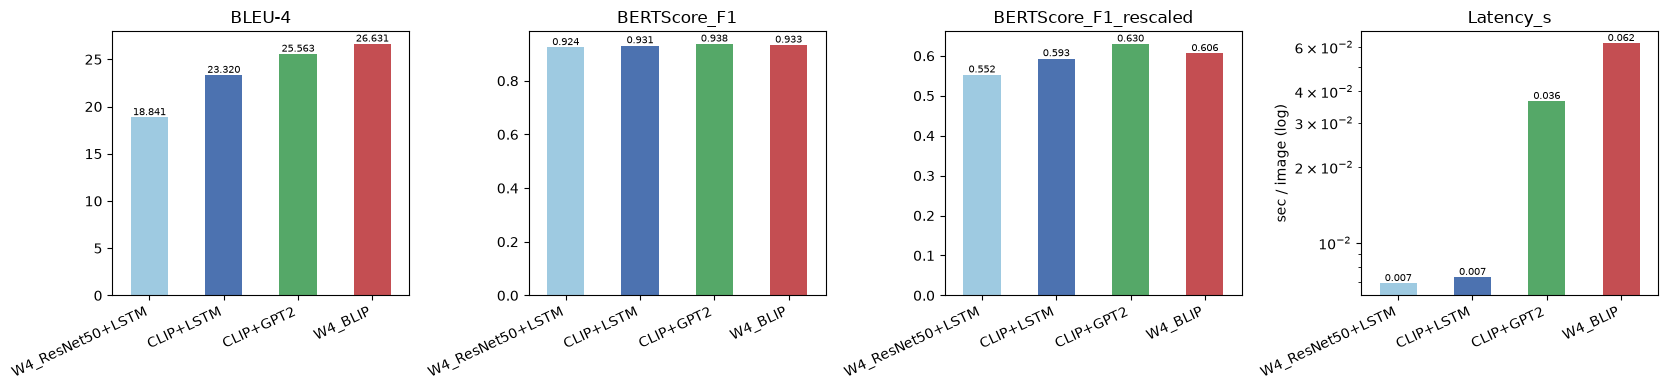

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q3_method_comparison.png


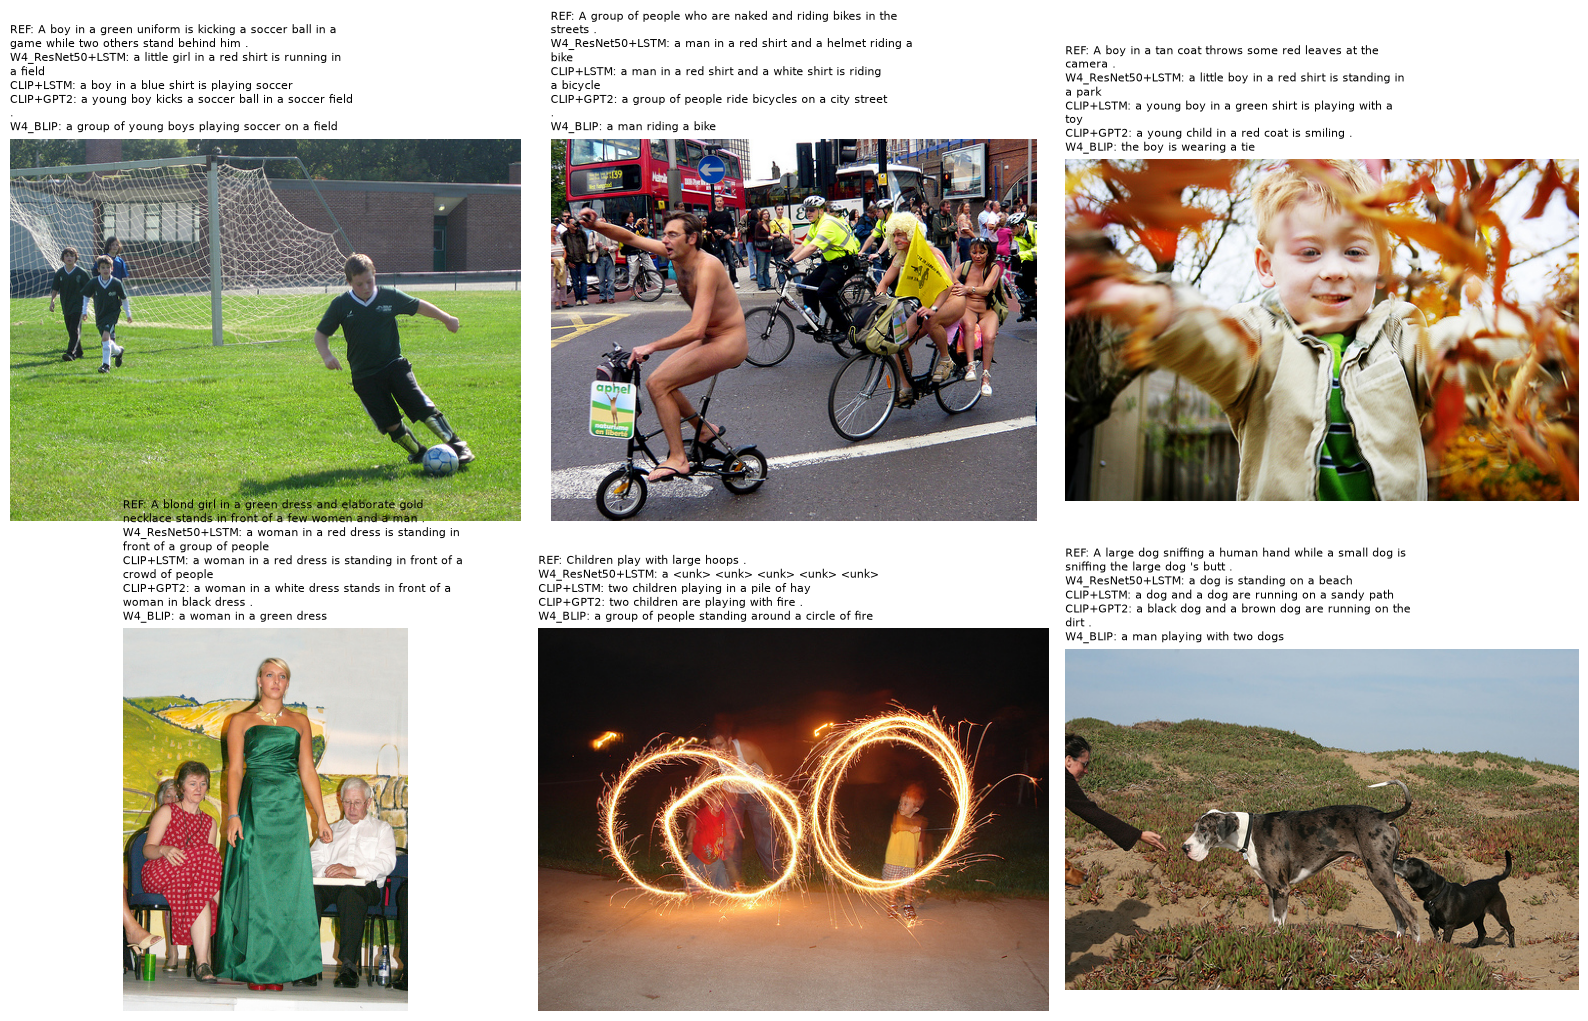

[saved] /cluster/home/m315832001/class/MMIP/week5/Outputs/Q3_caption_examples.png


In [16]:
q3.plot_comparison(ctx3, df3)
q3.plot_examples(ctx3)

### Quiz 3 結果分析

W4 基準為載入的 Week 4 模型（2.82M 參數、詞彙表 2,539 詞，未重新訓練）；其餘三個系統與 BLIP 為本次評估

| 系統 | BLEU-4 | BERTScore F1 | BERTScore (rescaled) | 平均字數 | 延遲 |
|---|---|---|---|---|---|
| W4_ResNet50+LSTM（載入 .pt） | 18.8 | 0.9245 | 0.553 | 10.8 | 6.9 ms |
| CLIP+LSTM | 23.3 | 0.9313 | 0.593 | 10.1 | 7.3 ms |
| CLIP+GPT2 | 25.6 | **0.9375** | **0.630** | 11.3 | 36.5 ms |
| W4_BLIP | **26.6** | 0.9335 | 0.606 | 6.8 | 62.0 ms |

1. **每一步改動都帶來提升，鑑別度良好**   
僅把 Encoder 換成 CLIP（解碼器架構相同、同為貪婪解碼），BLEU-4 由 18.8 升到 23.3（+4.5）、BERTScore（rescaled）由 0.553 升到 0.593（+0.041）；再換成 GPT-2 解碼器，BLEU-4 升到 25.6（+2.2）、rescaled 升到 0.630（+0.037）整體相對 Week 4 基準，BLEU-4 提升 6.7
2. **解碼策略是混淆因素**  
 CLIP+GPT2 使用 beam=3，LSTM 系統使用貪婪解碼，因此 CLIP+LSTM → CLIP+GPT2 的提升有一部分可能來自 beam search，而非解碼器架構本身；若要嚴謹歸因，可讓 CLIP+GPT2 也用貪婪解碼再比一次
3. **BERTScore 請看 rescaled 版本**   
原始 F1 全部擠在 0.925–0.938，幾乎看不出差別；rescaled 後差距才明顯

4. **與 BLIP 的比較**   
BLIP 的 BLEU-4 最高（26.6），但 CLIP+GPT2 的 BERTScore 較高（0.630 vs 0.606）BLIP 的描述平均只有 6.8 字，明顯短於其他系統（約 10–11 字），風格也與 Flickr8k 參考描述不同，推測為兩個指標排序不一致的原因
5. **速度與品質的取捨**  
 CLIP+LSTM 與 Week 4 基準速度相近（約 7 ms），但品質明顯較好，是最划算的改動；CLIP+GPT2 約 36.5 ms，約為 LSTM 系統的 5 倍，但仍比 BLIP（62 ms）快

6. **訓練行為（`Q3_training_curves.png`）**   
CLIP+LSTM 在第 26 epoch 達最佳 val loss（2.636），之後 3 個 epoch 沒有改善而停止；CLIP+GPT2 只到第 3 epoch 就最佳（2.2505），之後 val loss 回升，微調整個 GPT-2 很快過擬合兩者的 token-level loss 使用不同的詞彙／分詞方式（詞級 2,539 詞 vs GPT-2 BPE），**不能直接比較數值**圖中沒有 W4 曲線，因為 W4 是載入的
7. **定性觀察**   
以第一張 test 影像為例，Week 4 基準輸出「a brown dog is running through a field of a large black dog」，場景與語法都有問題；CLIP+LSTM（two dogs are playing in the snow）、CLIP+GPT2（two brown dogs are playing in the snow .）與 BLIP（two dogs playing in the snow）都描述為雪地中的兩隻狗這只是單一例子，更完整的對照見 `Q3_caption_examples.png`